# 02 · Train / Dev / Test Split

**What this notebook covers**

- Load the clean dataset and check its hash
- Split the data 70 / 15 / 15, stratified on `is_canceled`
- Check split sizes, class balance and that the splits do not overlap
- Plot the cancellation rate per split
- Save the splits and the split manifest

## 1. Environment setup
### 1.1 Imports

In [2]:
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

### 1.2 Configuration, seed and paths
All split parameters live here. Changing them invalidates every downstream artifact, so
they are recorded in the split manifest.

In [3]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "02"
SPLIT_RATIOS = {"train": 0.70, "dev": 0.15, "test": 0.15}
MAX_STRATIFICATION_GAP_PP = 0.5  # max allowed |split positive rate - overall| in percentage points

# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


### 1.3 Shared constants, helpers and plotting style

In [4]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

In [5]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

In [6]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,not installed
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,not installed


## 2. Load the clean dataset and verify it against the data contract
The hash check guarantees we split exactly the file notebook 01 produced. If it fails,
re-run notebook 01.

In [7]:
data_contract = load_json(PATHS["artifacts"] / "data_contract.json")
clean_sha256 = sha256_file(PATHS["clean"])
assert clean_sha256 == data_contract["clean"]["sha256"], "Clean file changed since notebook 01 - re-run notebook 01."

df = read_frame(PATHS["clean"])
assert list(df.shape) == data_contract["clean"]["shape"], "Shape differs from the data contract."
print(f"Clean dataset: {df.shape}, positive rate {df[TARGET].mean():.4f}")

Clean dataset: (87138, 31), positive rate 0.2728


## 3. Pre-split contract checks
Leakage columns must be absent and duplicates must already be removed. Dedup *after*
splitting would let a duplicate pair straddle Train and Test (decision #4).

In [8]:
assert not set(LEAKAGE_COLUMNS) & set(df.columns), "Leakage columns present before the split."
assert df[ID_COLUMN].is_unique, "booking_id is not unique."
assert not df.drop(columns=[ID_COLUMN]).duplicated().any(), "Duplicates present before the split."
print("Pre-split checks passed: no leakage columns, no duplicates, unique IDs.")

Pre-split checks passed: no leakage columns, no duplicates, unique IDs.


## 4. Two-stage stratified split
Stage 1 holds out Test (15 %). Stage 2 splits the remaining 85 % into Train and Dev with
`dev_share = 0.15 / 0.85`, giving 70 / 15 / 15 of the whole. Both stages stratify on the
target and use the same seed.

In [9]:
train_dev_df, test_df = train_test_split(
    df, test_size=SPLIT_RATIOS["test"], stratify=df[TARGET], random_state=RANDOM_STATE
)
dev_share_of_remainder = SPLIT_RATIOS["dev"] / (SPLIT_RATIOS["train"] + SPLIT_RATIOS["dev"])
train_df, dev_df = train_test_split(
    train_dev_df, test_size=dev_share_of_remainder, stratify=train_dev_df[TARGET], random_state=RANDOM_STATE
)
SPLITS = {"train": train_df, "dev": dev_df, "test": test_df}
{name: frame.shape for name, frame in SPLITS.items()}

{'train': (60996, 31), 'dev': (13071, 31), 'test': (13071, 31)}

## 5. Split integrity checks
### 5.1 Sizes and stratification
Each split must be within ±0.5 pp of the overall positive rate.

In [10]:
overall_rate = df[TARGET].mean()
split_summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "share_pct": len(frame) / len(df) * 100,
        "positives": int(frame[TARGET].sum()),
        "positive_rate_pct": frame[TARGET].mean() * 100,
        "gap_vs_overall_pp": (frame[TARGET].mean() - overall_rate) * 100,
    }
    for name, frame in SPLITS.items()
]).round(3)

assert split_summary["gap_vs_overall_pp"].abs().max() <= MAX_STRATIFICATION_GAP_PP, "Stratification gap too large."
assert split_summary["rows"].sum() == len(df), "Rows lost or duplicated during splitting."
split_summary.to_csv(PATHS["tables"] / "02_split_summary.csv", index=False)
split_summary

,split,rows,share_pct,positives,positive_rate_pct,gap_vs_overall_pp
0,train,60996,69.999,16637,27.276,0.000
1,dev,13071,15.000,3565,27.274,-0.001
2,test,13071,15.000,3565,27.274,-0.001


### 5.2 Disjointness by ID and by content
Disjoint IDs are necessary but not sufficient: two different IDs could still carry
identical content. We hash every row's feature content and assert no hash appears in
more than one split (validation-gate item "dedup happened pre-split").

In [11]:
id_sets = {name: set(frame[ID_COLUMN]) for name, frame in SPLITS.items()}
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    assert id_sets[a].isdisjoint(id_sets[b]), f"booking_id overlap between {a} and {b}"
assert set().union(*id_sets.values()) == set(df[ID_COLUMN]), "Union of splits differs from the clean dataset."

content_columns = [c for c in df.columns if c != ID_COLUMN]
content_hashes = {name: set(pd.util.hash_pandas_object(frame[content_columns], index=False)) for name, frame in SPLITS.items()}
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    overlap = len(content_hashes[a] & content_hashes[b])
    assert overlap == 0, f"{overlap} identical rows shared between {a} and {b}"
print("Splits are disjoint by booking_id and by full row content; union equals the clean dataset.")

Splits are disjoint by booking_id and by full row content; union equals the clean dataset.


### 5.3 Composition sanity check (not a stratification target)
A random split should give similar hotel and arrival-year mixes in each split. Large
differences would hint at a bug, and the year mix matters for the temporal robustness
check in notebook 14.

In [12]:
composition = pd.concat(
    {name: frame[["hotel", "arrival_date_year"]].astype(str).agg(" | ".join, axis=1).value_counts(normalize=True) * 100
     for name, frame in SPLITS.items()},
    axis=1,
).round(2).sort_index()
composition

,train,dev,test
City Hotel | 2015,7.47,7.32,7.64
City Hotel | 2016,30.57,31.26,30.20
City Hotel | 2017,23.16,22.65,22.78
Resort Hotel | 2015,7.76,7.41,8.03
Resort Hotel | 2016,17.97,17.77,17.65
Resort Hotel | 2017,13.08,13.58,13.70


### 5.4 Visual check: positive rate per split
One series, one axis: each split's cancellation rate against the overall rate.

Saved figure -> reports/figures/02_split_positive_rate.png


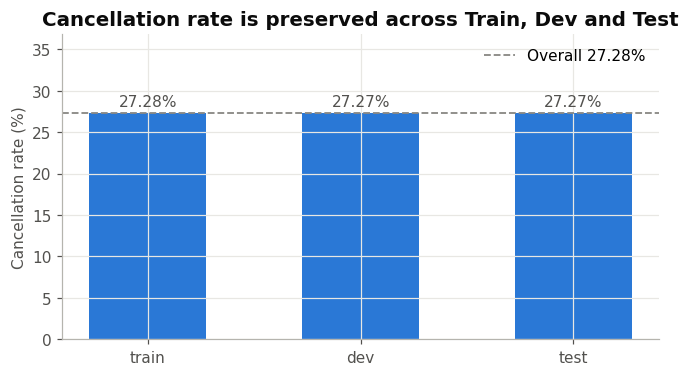

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(split_summary["split"], split_summary["positive_rate_pct"], color=COLORS["not_canceled"], width=0.55)
ax.axhline(overall_rate * 100, color=COLORS["neutral"], linestyle="--", linewidth=1.2, label=f"Overall {overall_rate:.2%}")
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in split_summary["positive_rate_pct"]], padding=3, color=COLORS["ink_muted"])
ax.set_ylabel("Cancellation rate (%)")
ax.set_ylim(0, overall_rate * 100 * 1.35)
ax.set_title("Cancellation rate is preserved across Train, Dev and Test")
ax.legend(loc="upper right")
save_figure(fig, "split_positive_rate")
plt.show()

## 6. Persist the splits and the split manifest
Splits are written once. Notebook 04 checks each file's hash against this manifest.

In [14]:
PATHS["splits"].mkdir(parents=True, exist_ok=True)
file_hashes = {}
for name, frame in SPLITS.items():
    path = PATHS["splits"] / f"{name}.csv"
    frame.sort_values(ID_COLUMN).to_csv(path, index=False)
    file_hashes[name] = sha256_file(path)

n_neg, n_pos = int((train_df[TARGET] == 0).sum()), int((train_df[TARGET] == 1).sum())
split_manifest = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "02_train_dev_test_split.ipynb",
    "source": {"path": data_contract["clean"]["path"], "sha256": clean_sha256},
    "random_state": RANDOM_STATE,
    "ratios": SPLIT_RATIOS,
    "stratify_on": TARGET,
    "sizes": {name: len(frame) for name, frame in SPLITS.items()},
    "positives": {name: int(frame[TARGET].sum()) for name, frame in SPLITS.items()},
    "positive_rate": {name: float(frame[TARGET].mean()) for name, frame in SPLITS.items()},
    "train_scale_pos_weight": n_neg / n_pos,
    "file_hashes": file_hashes,
    "library_versions": LIBRARY_VERSIONS,
}
save_json(split_manifest, PATHS["artifacts"] / "split_manifest.json")
pd.Series(split_manifest["sizes"], name="rows").to_frame()

,rows
train,60996
dev,13071
test,13071


## 7. Hand-off summary

- **Train / Dev / Test** written to `data/processed/splits/` with hashes in `artifacts/split_manifest.json`.
- `train_scale_pos_weight` in the manifest is the reference value for XGBoost (notebook 08).
- **Rule:** model notebooks (05–09) read the *feature* versions of Train and
  Dev only (written by notebook 04). The Test file is read only by notebook 14.
- Update `docs/04` §4.10 with the actual split sizes printed in §5.1 (plan issue I-01).